# O.A.S.I.S.: Orbital Adaptive Smart Irrigation & Sustenance
### LLM-assisted crop control for closed-loop space habitats

## 1. Overview

O.A.S.I.S. is a control loop for growing crops in a sealed habitat. It reads sensor telemetry, asks a language model what the actuators should do, and then passes that answer through fixed safety rules before anything would reach the hardware.

Each telemetry frame goes through four steps:

| Step | What happens | Where in this notebook |
| :--- | :--- | :--- |
| 1. Ingest | Read a frame: air temperature, relative humidity, substrate moisture, CO₂, LED temperature, reservoir level | Section 4 |
| 2. Derive | Compute vapor pressure deficit (VPD) from temperature and humidity | Section 4 |
| 3. Propose | Send the frame, the crop's target ranges and its space-specific risks to the model, which returns a control vector (irrigation volume, light spectrum, light intensity, fan duty) plus a short justification | Section 6 |
| 4. Validate | Clamp the proposal to hard limits (LED temperature, reservoir level, maximum irrigation volume) | Section 5 |

The model is only ever allowed to *propose*. The deterministic limits in step 4 have the final say, so a bad model output cannot, for example, run a pump dry or keep the lights at full power on an overheating LED array.

## 2. Model selection

Before building the pipeline, five models were benchmarked on the same anomalous Martian-greenhouse telemetry, three runs each. One ran locally on a Kaggle T4 GPU, the rest through Groq's cloud API. These figures come from that earlier benchmark and are not re-run in this notebook.

| Provider | Model | Run 1 (s) | Run 2 (s) | Run 3 (s) | Avg (s) | Valid JSON | Notes |
| :--- | :--- | ---: | ---: | ---: | ---: | :---: | :--- |
| Kaggle GPU (local) | `Qwen/Qwen2.5-7B-Instruct` | 36.929 | 38.797 | 37.259 | 37.662 | 3/3 | Very slow. Inverted cooling logic: `AIR_CONDITIONER: OFF` during high temperature |
| Groq | `llama-3.1-8b-instant` | 0.147 | 0.032 | 0.037 | 0.072 | 0/3 | API error 404 (bad endpoint string), so no usable output |
| Groq | `llama-3.3-70b-versatile` | 0.034 | 0.042 | 0.043 | 0.040 | 0/3 | API error 404 (bad endpoint string), so no usable output |
| Groq | `openai/gpt-oss-20b` | 1.666 | 1.286 | 1.926 | 1.626 | 3/3 | Fast, valid JSON, standard actuation logic |
| Groq | `openai/gpt-oss-120b` | 3.525 | 3.123 | 3.463 | 3.370 | 3/3 | **Selected.** Deeper reasoning, granular relay targets, strict EVA safety steps |

The two Llama rows failed because of a configuration error, not because of model quality, so their latencies are not meaningful.

## 3. Why `openai/gpt-oss-120b`

1. **Speed.** About 11× faster than local inference (3.37 s against 37.66 s, a 91% reduction), which is fast enough for a loop that handles a frame every few seconds.
2. **Correct control logic.** At 24.8 °C, above the 18–22 °C target, Qwen2.5-7B turned the air conditioning *off*. The 120B model chose the right interventions (`COOLING_FAN: ON`, `VENT_ACTUATOR: OPEN`).
3. **Hardware-addressable output.** It names precise relay targets (`IRRIGATION_PUMP`, `IRRIGATION_VALVE_MAIN`, `HUMIDIFIER_RELAY`) that could bind directly to a PLC.
4. **Safety-aware procedures.** Unprompted, it added habitat pressure checks (cabin pressure above 80 kPa) before clearing a maintenance hatch.

<center>
  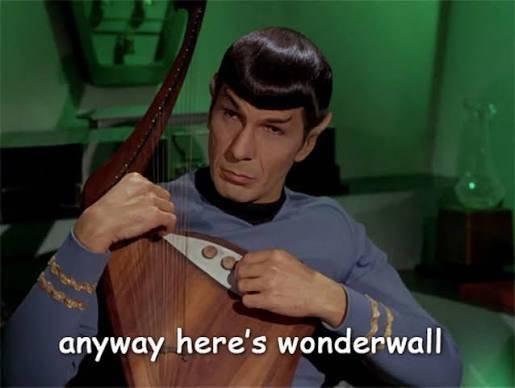
</center>

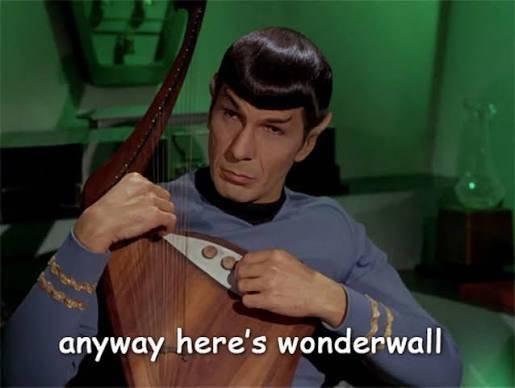

## 4. Setup and data

### 4.1 Dependencies and API key

The Groq key is read from the `GROQ_API_KEY` environment variable or, on Kaggle, from a notebook secret with the same name (*Add-ons → Secrets*). **Never paste a key into a cell**: it ends up in the saved notebook and in any copy you share.

If no key is found the notebook still runs. The controller then returns a fixed fallback vector and every affected frame is flagged, so you can test the rest of the pipeline offline.

In [1]:
%pip install -q groq

import json
import math
import os
import textwrap
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from groq import Groq

MODEL_ID = "openai/gpt-oss-120b"


def load_api_key():
    """Look for the key in the environment first, then in Kaggle secrets."""
    key = os.environ.get("GROQ_API_KEY")
    if key:
        return key
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("GROQ_API_KEY")
    except Exception:
        return None


GROQ_API_KEY = load_api_key()
groq_client = Groq(api_key=GROQ_API_KEY) if GROQ_API_KEY else None
print("Groq client ready." if groq_client else "No GROQ_API_KEY found: the controller will use its fallback vector.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 3.2 MB/s eta 0:00:00:00:01
Note: you may need to restart the kernel to use updated packages.
Groq client ready.


### 4.2 Crop knowledge base and VPD

`PLANT_KNOWLEDGE_BASE` holds, for each crop and growth stage, the target ranges the model is told to aim for (VPD, daily light integral, air temperature, substrate moisture) and the space-specific risks it should keep in mind. Only potato (tuber bulking) and dwarf tomato (fruiting) are defined.

**Vapor pressure deficit** measures how strongly the air pulls water out of the leaves. Too low and the plant cannot transpire. Too high and it loses water faster than the roots can supply it. It is computed from temperature $T$ (°C) and relative humidity $RH$ (%) with the Tetens approximation:

$$e_s = 0.61078 \cdot \exp\left(\frac{17.27\,T}{T + 237.3}\right) \qquad \mathrm{VPD} = e_s \cdot \left(1 - \frac{RH}{100}\right)$$

where $e_s$ is the saturation vapor pressure in kPa.

In [2]:
PLANT_KNOWLEDGE_BASE = {
    "potato": {
        "display_name": "Solanum tuberosum (Martian regolith)",
        "stages": {
            "tuber_bulking": {
                "vpd_target_kpa": (0.8, 1.2),
                "dli_target": 18,
                "temp_c": (18, 22),
                "soil_moisture_pct": (35, 45),
            }
        },
        "space_risks": [
            "Perchlorate soil saturation",
            "Substrate capillary waterlogging",
            "Root zone hypoxia",
        ],
    },
    "dwarf_tomato": {
        "display_name": "Solanum lycopersicum (hydroponic loop)",
        "stages": {
            "fruiting": {
                "vpd_target_kpa": (1.0, 1.4),
                "dli_target": 22,
                "temp_c": (21, 26),
                "soil_moisture_pct": (40, 50),
            }
        },
        "space_risks": [
            "Ethylene buildup during flowering",
            "Photosynthetic depression from high CO2",
        ],
    },
}


def calculate_vpd(temp_c: float, rh_pct: float) -> float:
    """Vapor pressure deficit in kPa (Tetens approximation)."""
    vp_sat = 0.61078 * math.exp((17.27 * temp_c) / (temp_c + 237.3))
    return round(vp_sat * (1 - rh_pct / 100.0), 3)

### 4.3 Telemetry dataset

The loader reads `oasis_telemetry_dataset.csv` if it exists. Otherwise it writes a small synthetic dataset: eight frames, 15 minutes apart, scripted so that the safety rules get exercised:

- **Frames 3–4:** temperature rises and humidity drops, so VPD climbs well above the potato target. In frame 4 the LED array passes its 60 °C limit.
- **Frames 5–6:** conditions return to normal.
- **Frames 7–8:** a second stress event. In frame 8 the water reservoir drops to 3.5%, below the dry-pump threshold.

In [3]:
DATA_PATH = Path("oasis_telemetry_dataset.csv")
TELEMETRY_COLUMNS = [
    "ambient_temp_c", "relative_humidity_pct", "soil_moisture_pct",
    "co2_ppm", "led_temp_c", "reservoir_level_pct",
]


def load_or_create_dataset(path: Path) -> pd.DataFrame:
    if path.exists():
        return pd.read_csv(path, parse_dates=["timestamp"])

    df = pd.DataFrame({
        "timestamp": pd.date_range("2026-10-12 00:00", periods=8, freq="15min"),
        "ambient_temp_c":        [20.1, 21.5, 24.8, 26.2, 21.0, 20.5, 23.0, 25.5],
        "relative_humidity_pct": [64.0, 58.0, 42.0, 38.0, 62.0, 65.0, 48.0, 40.0],
        "soil_moisture_pct":     [40.2, 35.0, 18.4, 15.0, 38.0, 41.0, 28.0, 16.0],
        "co2_ppm":               [950.0, 980.0, 940.0, 1100.0, 960.0, 950.0, 1020.0, 1150.0],
        "led_temp_c":            [38.0, 42.0, 52.0, 63.5, 39.0, 37.5, 58.0, 64.0],
        "reservoir_level_pct":   [80.0, 78.0, 75.0, 72.0, 70.0, 68.0, 65.0, 3.5],
    })
    df.to_csv(path, index=False)
    return df


dataset_df = load_or_create_dataset(DATA_PATH)
display(dataset_df)

,timestamp,ambient_temp_c,relative_humidity_pct,soil_moisture_pct,co2_ppm,led_temp_c,reservoir_level_pct
0,2026-10-12 00:00:00,20.1,64.0,40.2,950.0,38.0,80.0
1,2026-10-12 00:15:00,21.5,58.0,35.0,980.0,42.0,78.0
2,2026-10-12 00:30:00,24.8,42.0,18.4,940.0,52.0,75.0
3,2026-10-12 00:45:00,26.2,38.0,15.0,1100.0,63.5,72.0
4,2026-10-12 01:00:00,21.0,62.0,38.0,960.0,39.0,70.0
5,2026-10-12 01:15:00,20.5,65.0,41.0,950.0,37.5,68.0
6,2026-10-12 01:30:00,23.0,48.0,28.0,1020.0,58.0,65.0
7,2026-10-12 01:45:00,25.5,40.0,16.0,1150.0,64.0,3.5


## 5. Safety limits

Everything the model returns goes through `apply_safety_limits` before use. The function is plain Python with no model involved, so its behavior is predictable and testable. It enforces three rules, in this order:

| Rule | Condition | Action |
| :--- | :--- | :--- |
| `led_overtemp` | LED temperature ≥ 60 °C | Cap light intensity at 15% |
| `dry_reservoir` | Reservoir level < 5% | Set irrigation to 0 ml, which protects the pump from running dry |
| `irrigation_cap` | Requested irrigation > 150 ml | Reduce it to 150 ml |

It returns the corrected control vector together with a list of the interventions that fired, so the original proposal and the applied values can be compared later. Rules only ever *reduce* actuation; none of them invents a new command.

In [7]:
SAFETY_LIMITS = {
    "max_led_temp_c": 60.0,
    "led_overtemp_intensity_pct": 15,
    "min_reservoir_pct": 5.0,
    "max_irrigation_ml": 150,
}

RULE_LABELS = {
    "led_overtemp": "LED over-temperature",
    "dry_reservoir": "Dry-pump protection",
    "irrigation_cap": "Irrigation volume cap",
}


def apply_safety_limits(vector: dict, telemetry: dict):
    """Clamp a proposed control vector. Returns (safe_vector, interventions)."""
    safe = dict(vector)
    interventions = []

    def log(rule, message):
        interventions.append({"rule": rule, "message": message})

    if telemetry.get("led_temp_c", 0.0) >= SAFETY_LIMITS["max_led_temp_c"]:
        cap = SAFETY_LIMITS["led_overtemp_intensity_pct"]
        safe["light_intensity_pct"] = min(safe.get("light_intensity_pct", 100), cap)
        log("led_overtemp",
            f"LED at {telemetry['led_temp_c']} °C (limit {SAFETY_LIMITS['max_led_temp_c']}): light capped at {cap}%")

    if telemetry.get("reservoir_level_pct", 100.0) < SAFETY_LIMITS["min_reservoir_pct"]:
        safe["target_irrigation_ml"] = 0
        log("dry_reservoir",
            f"Reservoir at {telemetry['reservoir_level_pct']}% (minimum {SAFETY_LIMITS['min_reservoir_pct']}%): pump disabled")

    if safe.get("target_irrigation_ml", 0) > SAFETY_LIMITS["max_irrigation_ml"]:
        safe["target_irrigation_ml"] = SAFETY_LIMITS["max_irrigation_ml"]
        log("irrigation_cap",
            f"Irrigation reduced to the {SAFETY_LIMITS['max_irrigation_ml']} ml limit")

    return safe, interventions

## 6. Model controller

`query_controller` builds a prompt from the crop's targets, its space risks and the current telemetry frame (including the calculated VPD), sends it to the model with a low temperature (0.2) for consistent output, and parses the reply into a control vector.

The system prompt fixes the JSON schema: irrigation volume (0–150 ml), red:blue light ratio, light intensity (0–100%), fan duty (0–100%) and a short reasoning string.

Compared with simply calling `json.loads` on the reply, parsing here is a little more forgiving: it extracts the outermost `{ ... }` (models sometimes wrap JSON in code fences) and coerces the fields to numbers. If anything fails (no key, API error, malformed JSON) the function returns a fixed fallback vector and marks it `source: "fallback"`, so fallback frames are never mistaken for real model decisions.

In [8]:
FALLBACK_VECTOR = {
    "target_irrigation_ml": 45,
    "light_spectrum_ratio_r_b": 4.5,
    "light_intensity_pct": 80,
    "ventilation_fan_duty": 60,
}

SYSTEM_PROMPT = """You are O.A.S.I.S. (Orbital Adaptive Smart Irrigation & Sustenance), an AI bio-habitat control engine.
Analyze incoming telemetry, biophysical targets, and microgravity risk factors.
Output ONLY a valid JSON object matching this exact schema:
{
  "target_irrigation_ml": integer (0-150),
  "light_spectrum_ratio_r_b": float (Red to Blue ratio, e.g., 4.5),
  "light_intensity_pct": integer (0-100),
  "ventilation_fan_duty": integer (0-100),
  "reasoning": "Concise biological and physical justification."
}"""


def build_user_prompt(telemetry: dict, crop_id: str, stage: str) -> str:
    crop = PLANT_KNOWLEDGE_BASE.get(crop_id, PLANT_KNOWLEDGE_BASE["potato"])
    return (
        f"CROP: {crop['display_name']} | STAGE: {stage.upper()}\n"
        f"TARGET METRICS: {json.dumps(crop['stages'].get(stage, {}))}\n"
        f"SPACE RISKS: {crop['space_risks']}\n"
        f"INCOMING TELEMETRY FRAME: {json.dumps(telemetry, indent=2)}"
    )


def parse_vector(text: str) -> dict:
    """Extract and validate the JSON control vector from the model's reply."""
    text = text.strip()
    data = json.loads(text[text.find("{"): text.rfind("}") + 1])
    return {
        "target_irrigation_ml": int(round(float(data["target_irrigation_ml"]))),
        "light_spectrum_ratio_r_b": float(data["light_spectrum_ratio_r_b"]),
        "light_intensity_pct": int(round(float(data["light_intensity_pct"]))),
        "ventilation_fan_duty": int(round(float(data["ventilation_fan_duty"]))),
        "reasoning": str(data.get("reasoning", "")),
    }


def query_controller(telemetry: dict, crop_id: str = "potato", stage: str = "tuber_bulking") -> dict:
    """Ask the model for a control vector. Falls back to a fixed vector on any failure."""
    if groq_client is None:
        return {**FALLBACK_VECTOR, "reasoning": "Fallback vector: no Groq API key configured.", "source": "fallback"}
    try:
        response = groq_client.chat.completions.create(
            model=MODEL_ID,
            temperature=0.2,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": build_user_prompt(telemetry, crop_id, stage)},
            ],
        )
        return {**parse_vector(response.choices[0].message.content), "source": "model"}
    except Exception as exc:
        return {**FALLBACK_VECTOR, "reasoning": f"Fallback vector: {exc}", "source": "fallback"}

## 7. Running the pipeline

`stream_frames` turns each dataset row into a telemetry frame, the way a live sensor feed would deliver it. `process_frame` then runs one frame through the full chain: calculate VPD, ask the controller, apply the safety limits. `run_pipeline` repeats that for every frame.

Unlike the earlier version, which stopped after five frames, this runs **all eight**. The reservoir-failure frame is the last one, so stopping early meant the dry-pump rule was never exercised. Pass `max_frames=` to run fewer.

`build_results_table` flattens the records into one tidy DataFrame (one row per frame) that the summary table and all the charts below use.

In [9]:
def stream_frames(df: pd.DataFrame):
    """Yield one telemetry frame per dataset row."""
    for frame_id, (_, row) in enumerate(df.iterrows(), start=1):
        yield {
            "frame_id": frame_id,
            "timestamp": str(row["timestamp"]),
            **{col: float(row[col]) for col in TELEMETRY_COLUMNS},
        }


def process_frame(frame: dict, crop_id: str, stage: str) -> dict:
    vpd = calculate_vpd(frame["ambient_temp_c"], frame["relative_humidity_pct"])
    telemetry = {**frame, "calculated_vpd_kpa": vpd}

    raw_vector = query_controller(telemetry, crop_id=crop_id, stage=stage)
    safe_vector, interventions = apply_safety_limits(raw_vector, frame)

    return {
        "frame_id": frame["frame_id"],
        "telemetry": telemetry,
        "raw_vector": raw_vector,
        "safe_vector": safe_vector,
        "interventions": interventions,
    }


def run_pipeline(df: pd.DataFrame, crop_id: str = "potato", stage: str = "tuber_bulking", max_frames=None):
    records = []
    for frame in stream_frames(df):
        records.append(process_frame(frame, crop_id, stage))
        if max_frames and len(records) >= max_frames:
            break
    return records


def build_results_table(records: list) -> pd.DataFrame:
    rows = []
    for r in records:
        t, raw, safe = r["telemetry"], r["raw_vector"], r["safe_vector"]
        rows.append({
            "frame_id": r["frame_id"],
            "time": pd.Timestamp(t["timestamp"]),
            "temp_c": t["ambient_temp_c"],
            "rh_pct": t["relative_humidity_pct"],
            "vpd_kpa": t["calculated_vpd_kpa"],
            "soil_pct": t["soil_moisture_pct"],
            "co2_ppm": t["co2_ppm"],
            "led_temp_c": t["led_temp_c"],
            "reservoir_pct": t["reservoir_level_pct"],
            "irrigation_raw": raw["target_irrigation_ml"],  "irrigation": safe["target_irrigation_ml"],
            "light_raw": raw["light_intensity_pct"],        "light": safe["light_intensity_pct"],
            "fan_raw": raw["ventilation_fan_duty"],         "fan": safe["ventilation_fan_duty"],
            "rb_raw": raw["light_spectrum_ratio_r_b"],      "rb": safe["light_spectrum_ratio_r_b"],
            "interventions": [i["rule"] for i in r["interventions"]],
            "reasoning": safe.get("reasoning", ""),
            "source": raw["source"],
        })
    return pd.DataFrame(rows)


CROP_ID, STAGE = "potato", "tuber_bulking"

records = run_pipeline(dataset_df, CROP_ID, STAGE)
results = build_results_table(records)

### 7.1 Results table

One row per frame. Where the safety limits changed a value, the cell shows `proposed → applied`. For example, `70 → 15` means the model asked for 70% light and the limits reduced it to 15%.

In [10]:
def changed(raw, applied):
    return [f"{a:g}" if a == b else f"{a:g} → {b:g}" for a, b in zip(raw, applied)]


summary = pd.DataFrame({
    "time": results["time"].dt.strftime("%H:%M"),
    "VPD (kPa)": results["vpd_kpa"],
    "soil (%)": results["soil_pct"],
    "LED (°C)": results["led_temp_c"],
    "reservoir (%)": results["reservoir_pct"],
    "irrigation (ml)": changed(results["irrigation_raw"], results["irrigation"]),
    "light (%)": changed(results["light_raw"], results["light"]),
    "fan (%)": changed(results["fan_raw"], results["fan"]),
    "interventions": results["interventions"].map(lambda rules: ", ".join(rules) or "none"),
    "source": results["source"],
}).set_index("time")

display(summary)

,VPD (kPa),soil (%),LED (°C),reservoir (%),irrigation (ml),light (%),fan (%),interventions,source
time,,,,,,,,,
00:00,0.847,40.2,38.0,80.0,20,80,70,none,model
00:15,1.077,35.0,42.0,78.0,20,70,70,none,model
00:30,1.815,18.4,52.0,75.0,30,70,80,none,model
00:45,2.109,15.0,63.5,72.0,80,30 → 15,80,led_overtemp,model
01:00,0.945,38.0,39.0,70.0,20,62,55,none,model
01:15,0.844,41.0,37.5,68.0,20,70,40,none,model
01:30,1.461,28.0,58.0,65.0,30,70,80,none,model
01:45,1.958,16.0,64.0,3.5,45 → 0,70 → 15,80,"led_overtemp, dry_reservoir",model


### 7.2 Model reasoning

The justification the model gave for each frame, as returned in the `reasoning` field.

In [11]:
for _, row in results.iterrows():
    print(f"{row['time']:%H:%M}")
    print(textwrap.fill(row["reasoning"], width=100, initial_indent="  ", subsequent_indent="  "))
    print()

00:00
  Temperature (20.1 °C) and VPD (0.847 kPa) sit within the tuber‑bulking window (18‑22 °C,
  0.8‑1.2 kPa). Soil moisture is at 40.2 %, comfortably inside the 35‑45 % band, so only a modest
  water top‑up is needed to avoid perchlorate leaching, capillary waterlogging, and root‑zone
  hypoxia. A 20 ml irrigation pulse maintains moisture without oversaturation. To meet the DLI
  target of 18 mol m⁻² d⁻¹, an 80 % light intensity is appropriate, with a red‑to‑blue ratio of
  ~4.5:1 to promote tuber growth. LED temperature is elevated (38 °C), so a 70 % fan duty cycle
  provides sufficient airflow to dissipate heat while preserving CO₂ enrichment.

00:15
  Soil moisture is at the lower target bound (35%) and VPD is optimal; a modest 20 ml irrigation
  raises moisture toward the mid‑range (≈40%) while limiting perchlorate buildup and waterlogging
  risk. Tuber bulking benefits from a high red:blue ratio; a 5.5 : 1 ratio enhances tuber growth
  without excessive vegetative stretch. To a

## 8. Visualization

Three figures, each answering a different question. All are saved as PNGs next to the notebook.

| Figure | Question it answers |
| :--- | :--- |
| 8.1 Habitat conditions | What were the conditions, and when did they leave the target range or hit a safety limit? |
| 8.2 Proposed vs. applied | What did the model ask for, and what did the safety limits actually let through? |
| 8.3 Response check | Does the model respond in proportion to the problem? |

Every panel shows a single quantity in a single unit, so nothing is plotted against a rescaled or mixed axis.

In [12]:
C_LINE, C_BAD, C_BAND, C_RAW, C_INK = "#2b6f8f", "#d1495b", "#2a9d8f", "#8d99ae", "#2b2d42"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#b8bcc6",
    "axes.labelcolor": C_INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e8eaef",
    "grid.linewidth": 0.8,
    "xtick.color": C_INK,
    "ytick.color": C_INK,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})


def frame_half_width(results):
    """Half the spacing between frames, used to shade a frame's time slot."""
    if len(results) < 2:
        return pd.Timedelta(minutes=7)
    return results["time"].diff().median() / 2


def shade_interventions(ax, results, half):
    for t in results.loc[results["interventions"].map(bool), "time"]:
        ax.axvspan(t - half, t + half, color=C_BAD, alpha=0.08, lw=0)


def subtitle(results):
    n_fallback = int((results["source"] == "fallback").sum())
    text = f"{PLANT_KNOWLEDGE_BASE[CROP_ID]['display_name']}  ·  {STAGE.replace('_', ' ')}  ·  {len(results)} frames  ·  {MODEL_ID}"
    if n_fallback:
        text += f"  ·  {n_fallback} fallback frame(s)"
    return text

### 8.1 Habitat conditions

One panel per sensor reading, plus a timeline of safety interventions in the last panel.

- **Green band:** the crop's target range for the current growth stage.
- **Dashed red line:** a hard safety limit (LED ceiling, reservoir minimum).
- **Red points:** readings outside the target band or past a limit.
- **Pink shading (all panels):** frames in which at least one safety rule fired.

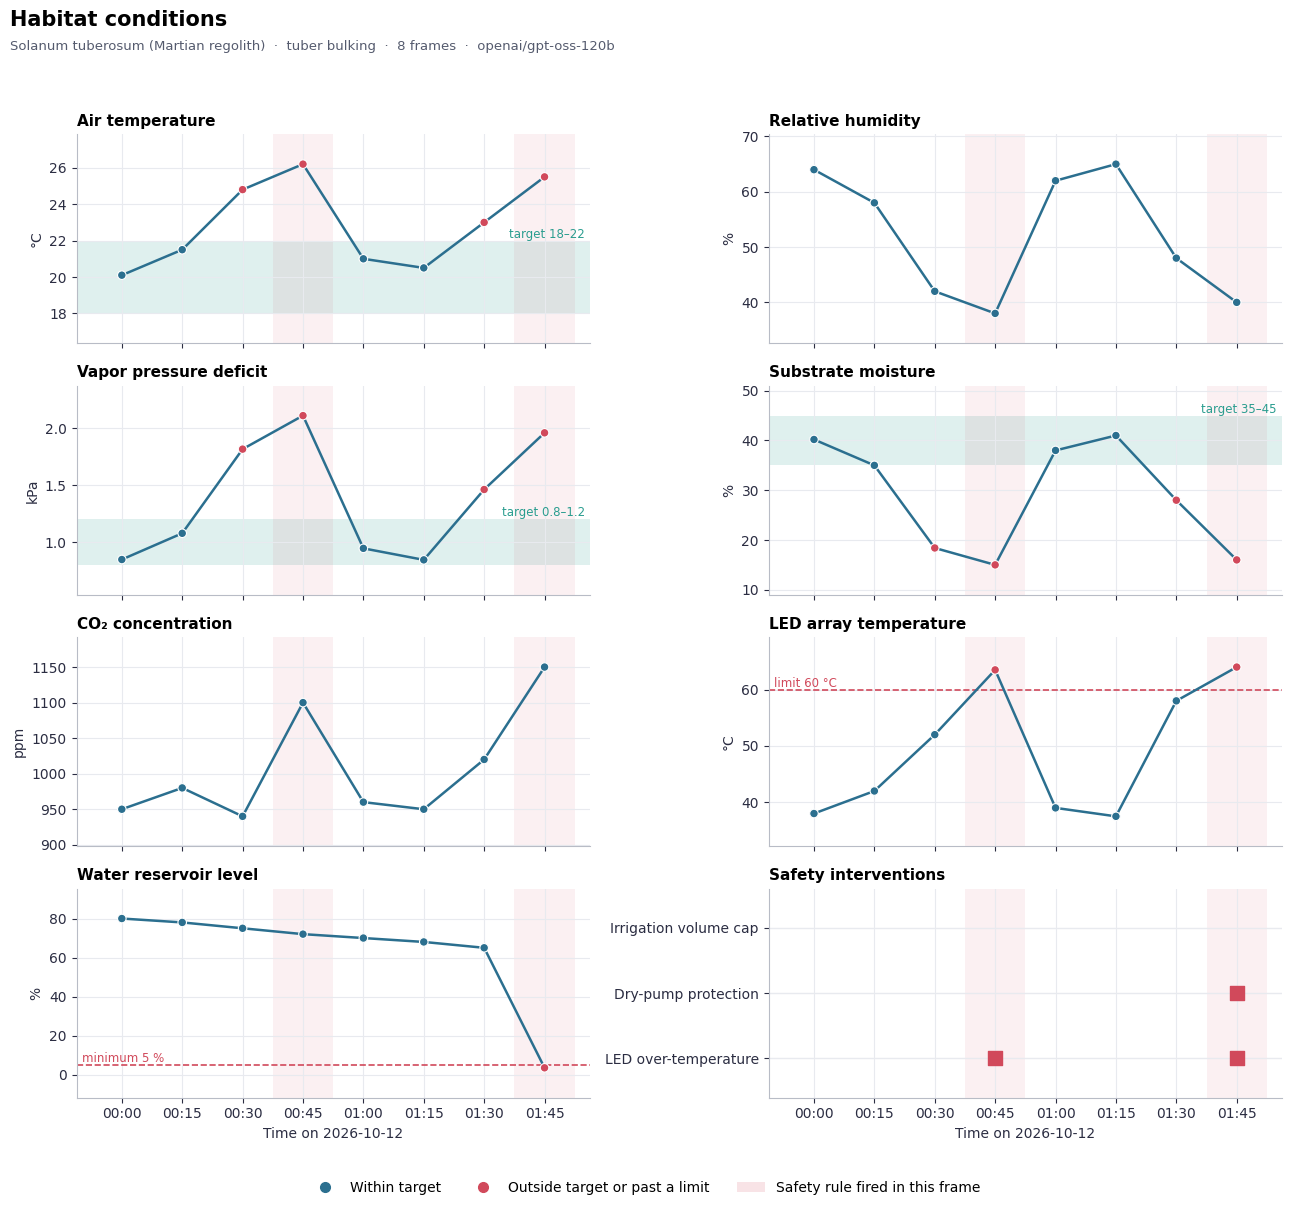

In [13]:
def plot_conditions(results, crop_id, stage):
    targets = PLANT_KNOWLEDGE_BASE[crop_id]["stages"][stage]
    panels = [
        dict(col="temp_c",        title="Air temperature",         unit="°C",  band=targets["temp_c"]),
        dict(col="rh_pct",        title="Relative humidity",       unit="%"),
        dict(col="vpd_kpa",       title="Vapor pressure deficit",  unit="kPa", band=targets["vpd_target_kpa"]),
        dict(col="soil_pct",      title="Substrate moisture",      unit="%",   band=targets["soil_moisture_pct"]),
        dict(col="co2_ppm",       title="CO₂ concentration",       unit="ppm"),
        dict(col="led_temp_c",    title="LED array temperature",   unit="°C",  ceiling=SAFETY_LIMITS["max_led_temp_c"]),
        dict(col="reservoir_pct", title="Water reservoir level",   unit="%",   floor=SAFETY_LIMITS["min_reservoir_pct"]),
    ]

    half = frame_half_width(results)
    fig, axes = plt.subplots(4, 2, figsize=(13, 12), sharex=True)
    axes = axes.ravel()

    for ax, p in zip(axes, panels):
        y = results[p["col"]]
        outside = pd.Series(False, index=y.index)
        yaxis_tf = ax.get_yaxis_transform()

        if "band" in p:
            lo, hi = p["band"]
            ax.axhspan(lo, hi, color=C_BAND, alpha=0.15, lw=0)
            ax.text(0.99, hi, f"target {lo:g}–{hi:g}", transform=yaxis_tf, ha="right", va="bottom", fontsize=8.5, color=C_BAND)
            outside = (y < lo) | (y > hi)
        if "ceiling" in p:
            ax.axhline(p["ceiling"], color=C_BAD, ls="--", lw=1.2)
            ax.text(0.01, p["ceiling"], f"limit {p['ceiling']:g} {p['unit']}", transform=yaxis_tf, ha="left", va="bottom", fontsize=8.5, color=C_BAD)
            outside = y >= p["ceiling"]
        if "floor" in p:
            ax.axhline(p["floor"], color=C_BAD, ls="--", lw=1.2)
            ax.text(0.01, p["floor"], f"minimum {p['floor']:g} {p['unit']}", transform=yaxis_tf, ha="left", va="bottom", fontsize=8.5, color=C_BAD)
            outside = y < p["floor"]

        shade_interventions(ax, results, half)
        ax.plot(results["time"], y, color=C_LINE, lw=1.8, zorder=2)
        ax.scatter(results["time"], y, c=np.where(outside, C_BAD, C_LINE), s=38, zorder=3, edgecolor="white", linewidth=0.8)
        ax.set_title(p["title"])
        ax.set_ylabel(p["unit"])
        ax.margins(y=0.2)

    # Last panel: which safety rules fired, and when.
    ax = axes[7]
    rules = list(RULE_LABELS)
    shade_interventions(ax, results, half)
    ax.grid(axis="y", visible=False)
    for i, rule in enumerate(rules):
        ax.axhline(i, color="#e8eaef", lw=1, zorder=1)
        times = results.loc[results["interventions"].map(lambda r: rule in r), "time"]
        ax.scatter(times, [i] * len(times), marker="s", s=90, color=C_BAD, zorder=3)
    ax.set_yticks(range(len(rules)))
    ax.set_yticklabels([RULE_LABELS[r] for r in rules])
    ax.set_ylim(-0.6, len(rules) - 0.4)
    ax.set_title("Safety interventions")
    if not results["interventions"].map(bool).any():
        ax.text(0.5, 0.5, "none triggered", transform=ax.transAxes, ha="center", va="center", color=C_RAW)

    axes[0].set_xlim(results["time"].min() - half * 1.5, results["time"].max() + half * 1.5)
    for ax in axes[-2:]:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.set_xlabel(f"Time on {results['time'].iloc[0]:%Y-%m-%d}")

    handles = [
        plt.Line2D([], [], color=C_LINE, marker="o", ls="", ms=7, label="Within target"),
        plt.Line2D([], [], color=C_BAD, marker="o", ls="", ms=7, label="Outside target or past a limit"),
        plt.Rectangle((0, 0), 1, 1, color=C_BAD, alpha=0.15, lw=0, label="Safety rule fired in this frame"),
    ]
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
    fig.suptitle("Habitat conditions", fontsize=15, fontweight="bold", x=0.01, ha="left", y=0.995)
    fig.text(0.01, 0.962, subtitle(results), fontsize=9.5, color="#555b6e", ha="left")
    fig.tight_layout(rect=(0, 0.04, 1, 0.95))
    fig.savefig("oasis_conditions.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_conditions(results, CROP_ID, STAGE)

### 8.2 Proposed vs. applied control vector

One panel per actuator setting. Hollow grey markers are what the model **proposed**. Filled blue markers are what was **applied** after the safety limits. When the two differ, a red bar connects them and the applied value is written next to it. Where there is no red bar, the model's proposal went through unchanged.

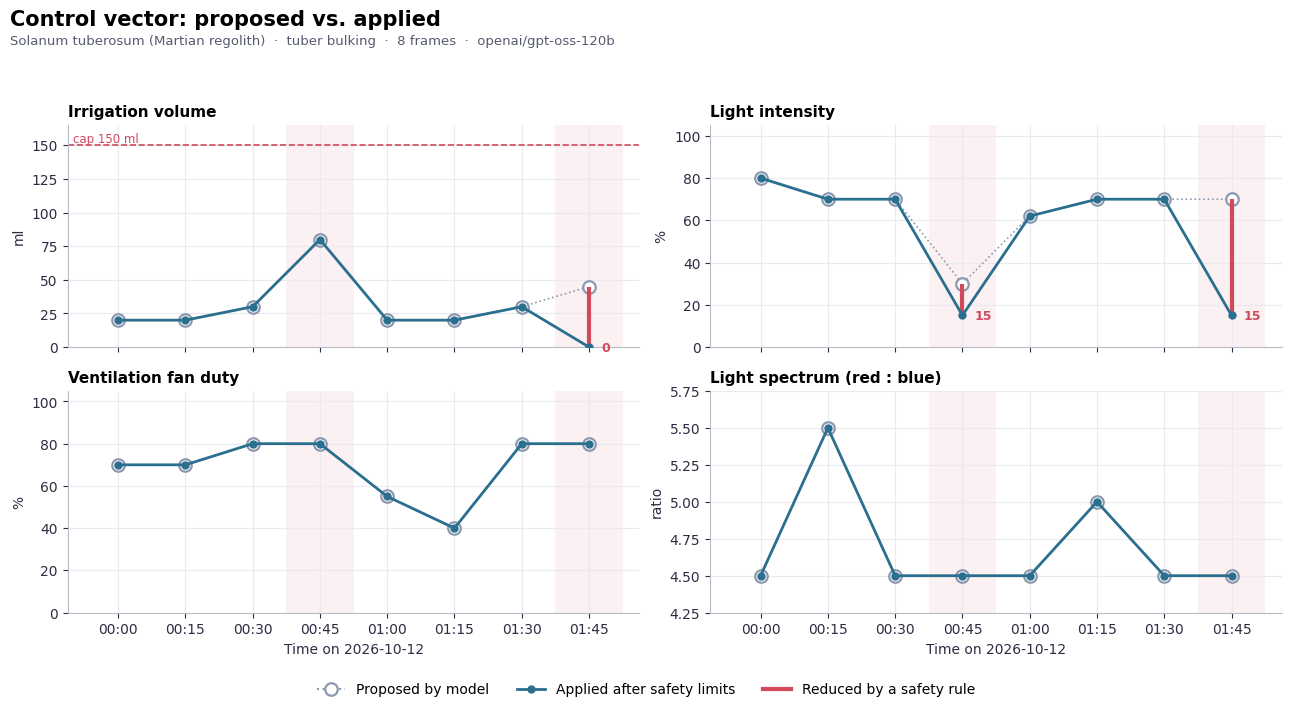

In [14]:
def plot_controller_output(results):
    specs = [
        dict(key="irrigation", title="Irrigation volume",     unit="ml",  ylim=(0, 165), cap=SAFETY_LIMITS["max_irrigation_ml"]),
        dict(key="light",      title="Light intensity",       unit="%",   ylim=(0, 105)),
        dict(key="fan",        title="Ventilation fan duty",  unit="%",   ylim=(0, 105)),
        dict(key="rb",         title="Light spectrum (red : blue)", unit="ratio", ylim=None),
    ]

    half = frame_half_width(results)
    fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)

    for ax, s in zip(axes.ravel(), specs):
        raw, applied, t = results[f"{s['key']}_raw"], results[s["key"]], results["time"]

        shade_interventions(ax, results, half)
        if "cap" in s:
            ax.axhline(s["cap"], color=C_BAD, ls="--", lw=1.2)
            ax.text(0.01, s["cap"], f"cap {s['cap']} {s['unit']}", transform=ax.get_yaxis_transform(),
                    ha="left", va="bottom", fontsize=8.5, color=C_BAD)

        ax.plot(t, raw, color=C_RAW, ls=":", lw=1.2, marker="o", ms=9, mfc="white", mec=C_RAW, mew=1.6, zorder=2)
        ax.plot(t, applied, color=C_LINE, lw=2, marker="o", ms=5, zorder=3)

        diff = raw != applied
        ax.vlines(t[diff], applied[diff], raw[diff], color=C_BAD, lw=3, zorder=2)
        for ti, a in zip(t[diff], applied[diff]):
            ax.annotate(f"{a:g}", (ti, a), textcoords="offset points", xytext=(9, -3),
                        fontsize=9, fontweight="bold", color=C_BAD)

        ax.set_title(s["title"])
        ax.set_ylabel(s["unit"])
        if s["ylim"]:
            top = max(s["ylim"][1], raw.max() * 1.08)
            ax.set_ylim(s["ylim"][0], top)
        else:
            ax.margins(y=0.25)

    axes[0, 0].set_xlim(results["time"].min() - half * 1.5, results["time"].max() + half * 1.5)
    for ax in axes[-1]:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.set_xlabel(f"Time on {results['time'].iloc[0]:%Y-%m-%d}")

    handles = [
        plt.Line2D([], [], color=C_RAW, ls=":", marker="o", mfc="white", ms=9, mew=1.6, label="Proposed by model"),
        plt.Line2D([], [], color=C_LINE, marker="o", ms=5, lw=2, label="Applied after safety limits"),
        plt.Line2D([], [], color=C_BAD, lw=3, label="Reduced by a safety rule"),
    ]
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
    fig.suptitle("Control vector: proposed vs. applied", fontsize=15, fontweight="bold", x=0.01, ha="left", y=0.995)
    fig.text(0.01, 0.945, subtitle(results), fontsize=9.5, color="#555b6e", ha="left")
    fig.tight_layout(rect=(0, 0.05, 1, 0.93))
    fig.savefig("oasis_controller_output.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_controller_output(results)

### 8.3 Response check

A quick test of whether the model's judgment is sensible, using its *proposed* values (before the safety limits). Each point is one frame, labelled with its frame number.

- **Left:** the further substrate moisture falls below the middle of the target range, the more water the model should request.
- **Right:** the further VPD rises above the top of the target range, the more ventilation the model should request.

A dashed trend line is drawn when there is enough variation. Points hugging a rising line mean the model reacts in proportion to the problem. A flat cloud means it is ignoring the input, which is what you will see if the notebook ran on the fixed fallback vector.

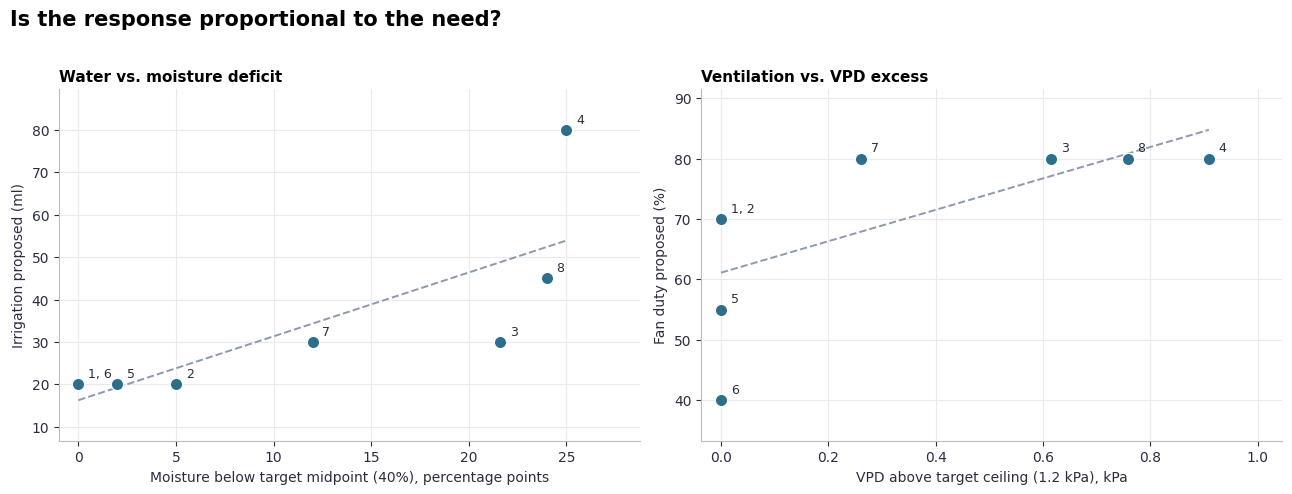

In [15]:
def plot_response_check(results, crop_id, stage):
    targets = PLANT_KNOWLEDGE_BASE[crop_id]["stages"][stage]
    soil_lo, soil_hi = targets["soil_moisture_pct"]
    soil_mid = (soil_lo + soil_hi) / 2
    vpd_hi = targets["vpd_target_kpa"][1]

    panels = [
        dict(x=(soil_mid - results["soil_pct"]).clip(lower=0), y=results["irrigation_raw"],
             xlabel=f"Moisture below target midpoint ({soil_mid:g}%), percentage points",
             ylabel="Irrigation proposed (ml)", title="Water vs. moisture deficit"),
        dict(x=(results["vpd_kpa"] - vpd_hi).clip(lower=0), y=results["fan_raw"],
             xlabel=f"VPD above target ceiling ({vpd_hi:g} kPa), kPa",
             ylabel="Fan duty proposed (%)", title="Ventilation vs. VPD excess"),
    ]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, p in zip(axes, panels):
        ax.scatter(p["x"], p["y"], s=80, color=C_LINE, edgecolor="white", linewidth=1, zorder=3)
        groups = {}
        for fid, xi, yi in zip(results["frame_id"], p["x"], p["y"]):
            groups.setdefault((xi, yi), []).append(str(fid))
        for (xi, yi), ids in groups.items():
            ax.annotate(", ".join(ids), (xi, yi), textcoords="offset points", xytext=(7, 5), fontsize=9, color=C_INK)
        if p["x"].nunique() > 1 and p["y"].nunique() > 1:
            slope, intercept = np.polyfit(p["x"], p["y"], 1)
            xs = np.array([p["x"].min(), p["x"].max()])
            ax.plot(xs, slope * xs + intercept, color=C_RAW, ls="--", lw=1.4, zorder=2)
        ax.set_xlabel(p["xlabel"])
        ax.set_ylabel(p["ylabel"])
        ax.set_title(p["title"])
        ax.margins(0.15)
        ax.set_xlim(left=-0.04 * max(p["x"].max(), 1e-9))

    fig.suptitle("Is the response proportional to the need?", fontsize=15, fontweight="bold", x=0.01, ha="left", y=1.02)
    fig.tight_layout()
    fig.savefig("oasis_response_check.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_response_check(results, CROP_ID, STAGE)

## 9. Notes and limitations

- **The dataset is synthetic.** Eight frames scripted to trigger the safety rules. Real telemetry would be noisier and far longer.
- **The benchmark is not reproduced here.** The model comparison in section 2 was a separate run. Latencies depend on load and on the Groq service at the time.
- **Latency only matters per frame.** Each frame costs one blocking API call (about 3 s for the selected model). Frames are processed one after another, which is fine for a loop that runs every few minutes but would need batching or concurrency at higher rates.
- **Safety rules are narrow.** They cover three hazards. They do not check fan duty, light spectrum or irrigation *frequency*, and nothing stops the model from proposing a poor but technically allowed action. Section 8.3 is a sanity check, not a guarantee.
- **One crop at a time.** `CROP_ID` and `STAGE` are set once for the whole run. Potato and dwarf tomato are defined in the knowledge base; adding a crop means adding an entry there.
- **Fallback frames are flagged, not hidden.** Without a key, or after an API error, the `source` column and the chart subtitle show how many frames used the fixed vector instead of a model decision.

<img src="https://38.media.tumblr.com/ecda70ff6d13ed92e1a277c090873146/tumblr_nvrz5nj5hm1qg1zuyo3_500.gif" width="500" alt="The Martian Disco GIF" style="display: block; margin: 0 auto;" />
